# 01  Feature extraction from the raw vibration data

Reads every recording of the case study directly from the raw Excel files, computes the
Hilbert squared envelope spectrum (SES) of the full 10 s signal and of each 1 s segment,
and selects the 1x and 2x BPFO peaks (maximum inside +/- 5 Hz of each harmonic).

Outputs (in `OUTPUT_DIR`):
* `features/features_full.csv`: one row per recording (160 rows)
* `features/features_segmented.csv`: one row per 1 s segment (1600 rows)
* `peak_verification/`: SES with the selected peaks (red dots) for every recording, full signal and first segment

Columns: `health, test, case, recording, [segment], A1, A2, f1, f2`, where A1 and A2 are the
selected peak amplitudes at 1x and 2x BPFO and f1, f2 the frequencies at which they were found.

This is the only notebook that needs the raw data. The two feature tables it produces are included in `outputs/features/`, so `02_analysis.ipynb` and `03_paper_figures.ipynb` can be run without the raw data.

In [ ]:
%pip install -r requirements.txt

In [2]:
from pathlib import Path
import time
import pandas as pd
from IPython.display import Image, display

import uncertainty_core as uc

# ---- edit these two paths -------------------------------------------------
DATA_ROOT  = Path("path/to/Bearing_Orig_data")   # folder that holds Healthy/ and Damage/
OUTPUT_DIR = Path("outputs")
# ---------------------------------------------------------------------------
N_JOBS = 4               # parallel processes; 1 = run one file at a time
SAVE_PEAK_PLOTS = True   # peak verification figure for every recording

cfg = uc.Config(data_root=DATA_ROOT, output_dir=OUTPUT_DIR)
print(f"fs = {cfg.fs} Hz, {cfg.duration_s} s per recording, {cfg.n_segments} x {cfg.segment_s} s segments")
print(f"NFFT = 2^{cfg.nfft.bit_length() - 1}, BPFO = {cfg.bpfo_hz} Hz, search band = +/- {cfg.half_band_hz} Hz")
print(f"Excel column {cfg.channel_col} (header must contain '{cfg.channel_label_contains}'), data from row {cfg.data_start_row}")

fs = 48000 Hz, 10.0 s per recording, 10 x 1.0 s segments
NFFT = 2^22, BPFO = 276.27 Hz, search band = +/- 5.0 Hz
Excel column 2 (header must contain 'X'), data from row 49


## 1. Self-tests of the core classes

In [3]:
uc.run_self_tests()

All self-tests passed.


## 2. Check that all 160 raw files are present

In [4]:
loader = uc.RawDataLoader(cfg)
files = loader.check_files()
print(f"Excel reader: {loader.engine}")
print(f"Files found: {int(files.exists.sum())} of {len(files)}")
display(files[~files.exists])

Excel reader: calamine
Files found: 160 of 160


,health,test,case,recording,path,exists,size_bytes


## 3. Extract features (slow step: about 10 s per recording per process)

In [5]:
fx = uc.FeatureExtractor(cfg)
peak_dir = cfg.subdir("peak_verification") if SAVE_PEAK_PLOTS else None
t0 = time.time()
full, seg = fx.extract_all(n_jobs=N_JOBS, peak_plot_dir=peak_dir)
print(f"Done in {(time.time() - t0) / 60:.1f} min")

store = uc.FeatureStore(full, seg)
store.save(cfg.subdir("features"))
print(f"Saved {len(full)} full-signal rows and {len(seg)} segment rows to {cfg.subdir('features')}")

[ 10/160] done  (    68 s)
[ 20/160] done  (   107 s)
[ 30/160] done  (   156 s)
[ 40/160] done  (   193 s)
[ 50/160] done  (   234 s)
[ 60/160] done  (   276 s)
[ 70/160] done  (   314 s)
[ 80/160] done  (   359 s)
[ 90/160] done  (   396 s)
[100/160] done  (   437 s)
[110/160] done  (   482 s)
[120/160] done  (   520 s)
[130/160] done  (   572 s)
[140/160] done  (   613 s)
[150/160] done  (   650 s)
[160/160] done  (   692 s)
Done in 11.6 min
Saved 160 full-signal rows and 1600 segment rows to outputs\features


## 4. Where were the peaks found?

Frequency range of the selected peaks per health state and test. A peak lying on the edge of
the search band (within one FFT bin) is listed separately.

In [6]:
bin_hz = cfg.fs / cfg.nfft
summary = []
for level, df in (("full", full), ("segmented", seg)):
    g = df.groupby(["health", "test"])[["f1", "f2"]].agg(["min", "max"]).round(2)
    g.insert(0, "level", level)
    summary.append(g)
display(pd.concat(summary))

edges = []
for level, df in (("full", full), ("segmented", seg)):
    for k, ft in zip(("f1", "f2"), cfg.targets_hz):
        e = df[(df[k] - (ft - cfg.half_band_hz)).abs().le(bin_hz) | (df[k] - (ft + cfg.half_band_hz)).abs().le(bin_hz)]
        if len(e):
            edges.append(e.assign(level=level, harmonic=k))
print(f"Peaks on the band edge: {sum(len(e) for e in edges)} "
      f"(of {2 * (len(full) + len(seg))} selected peaks)")
if edges:
    display(pd.concat(edges).groupby(["level", "health", "harmonic"]).size().rename("n_on_edge").to_frame())

level      f1              f2        
                            min     max     min     max
health  test                                           
damaged T1         full  274.84  275.64  549.68  551.28
        T2         full  275.15  276.24  549.72  552.47
        T3         full  274.86  276.73  547.55  554.63
        T4         full  275.07  277.35  548.27  557.46
healthy T1         full  273.56  280.86  547.97  556.90
        T2         full  272.43  279.19  548.02  555.94
        T3         full  271.92  280.96  550.22  557.52
        T4         full  271.61  279.40  547.79  556.70
damaged T1    segmented  271.43  275.77  548.71  557.28
        T2    segmented  275.02  276.55  547.54  557.53
        T3    segmented  274.73  277.59  547.54  557.53
        T4    segmented  274.88  277.68  547.54  557.53
healthy T1    segmented  271.27  281.26  547.54  557.53
        T2    segmented  271.27  281.26  547.54  557.53
        T3    segmented  271.27  281.26  547.54  557.53
        T4    segmented  271.27  281.26  547.54  557.53

Peaks on the band edge: 112 (of 3520 selected peaks)


n_on_edge
level     health  harmonic           
segmented damaged f2               18
          healthy f1               43
                  f2               51

## 5. Representative peak verification (test T2, case C1, recording R1)

peaks_healthy_T2_C1_R1_full.png


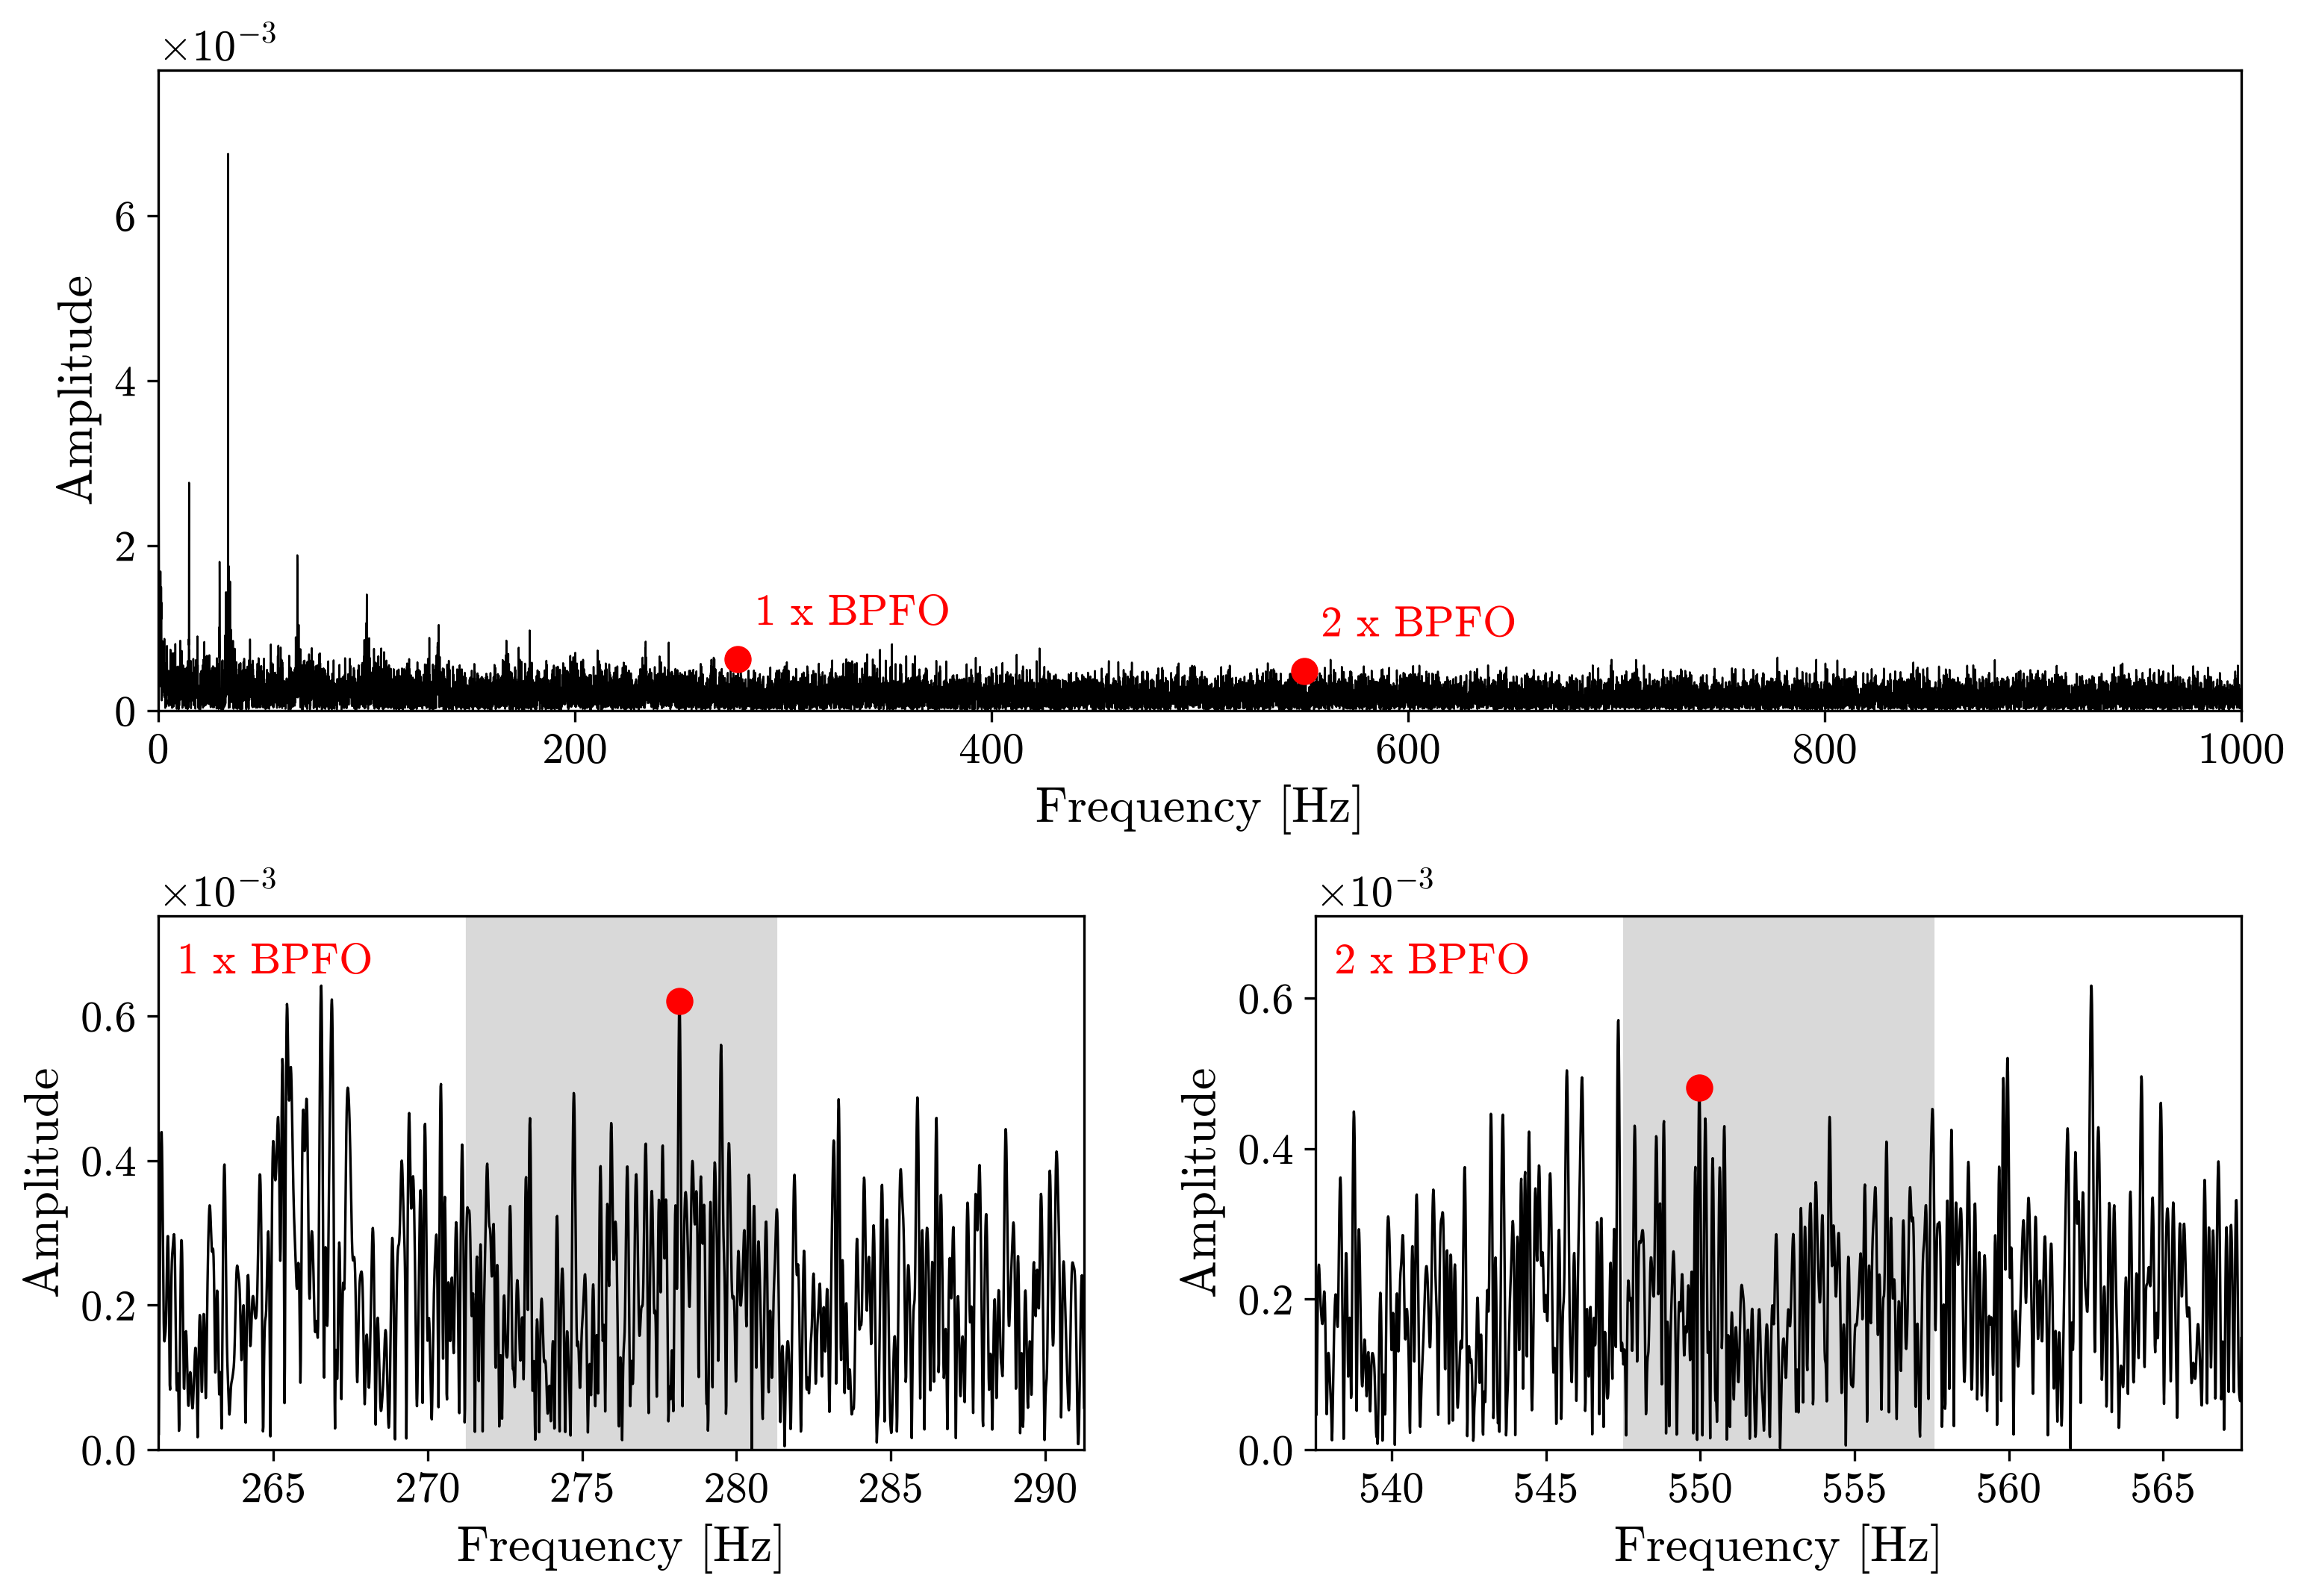

peaks_healthy_T2_C1_R1_segment01.png


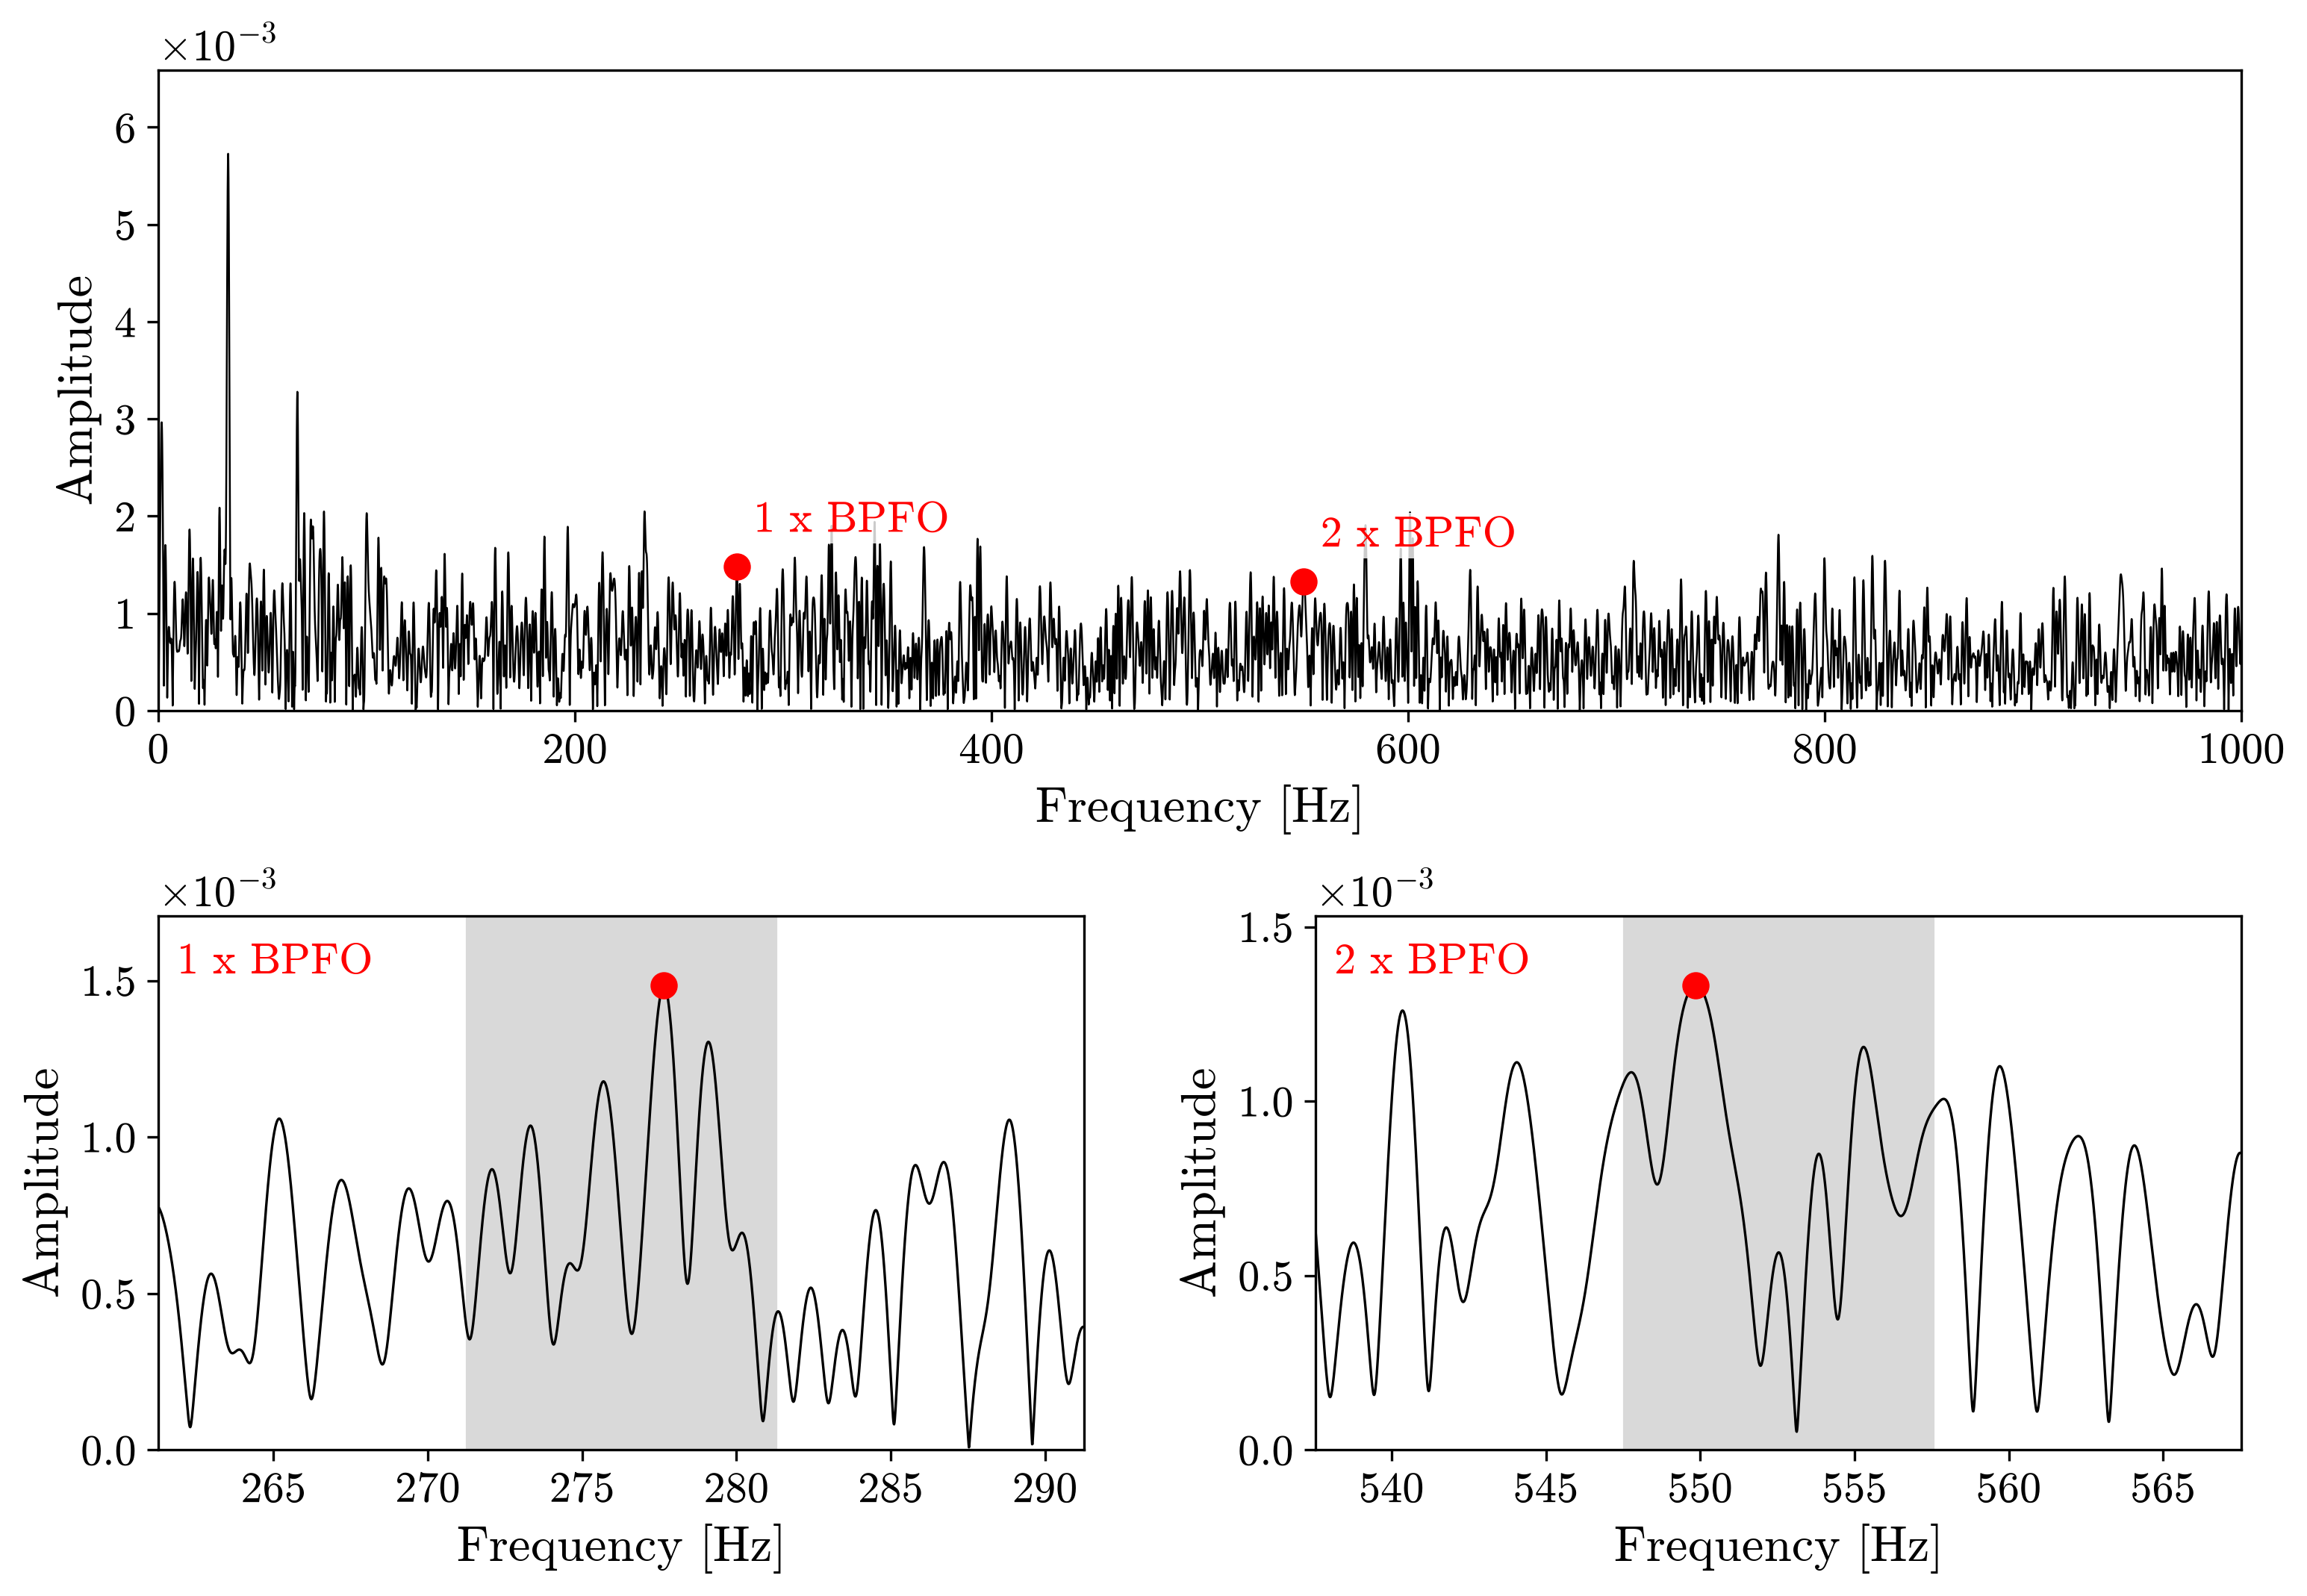

peaks_damaged_T2_C1_R1_full.png


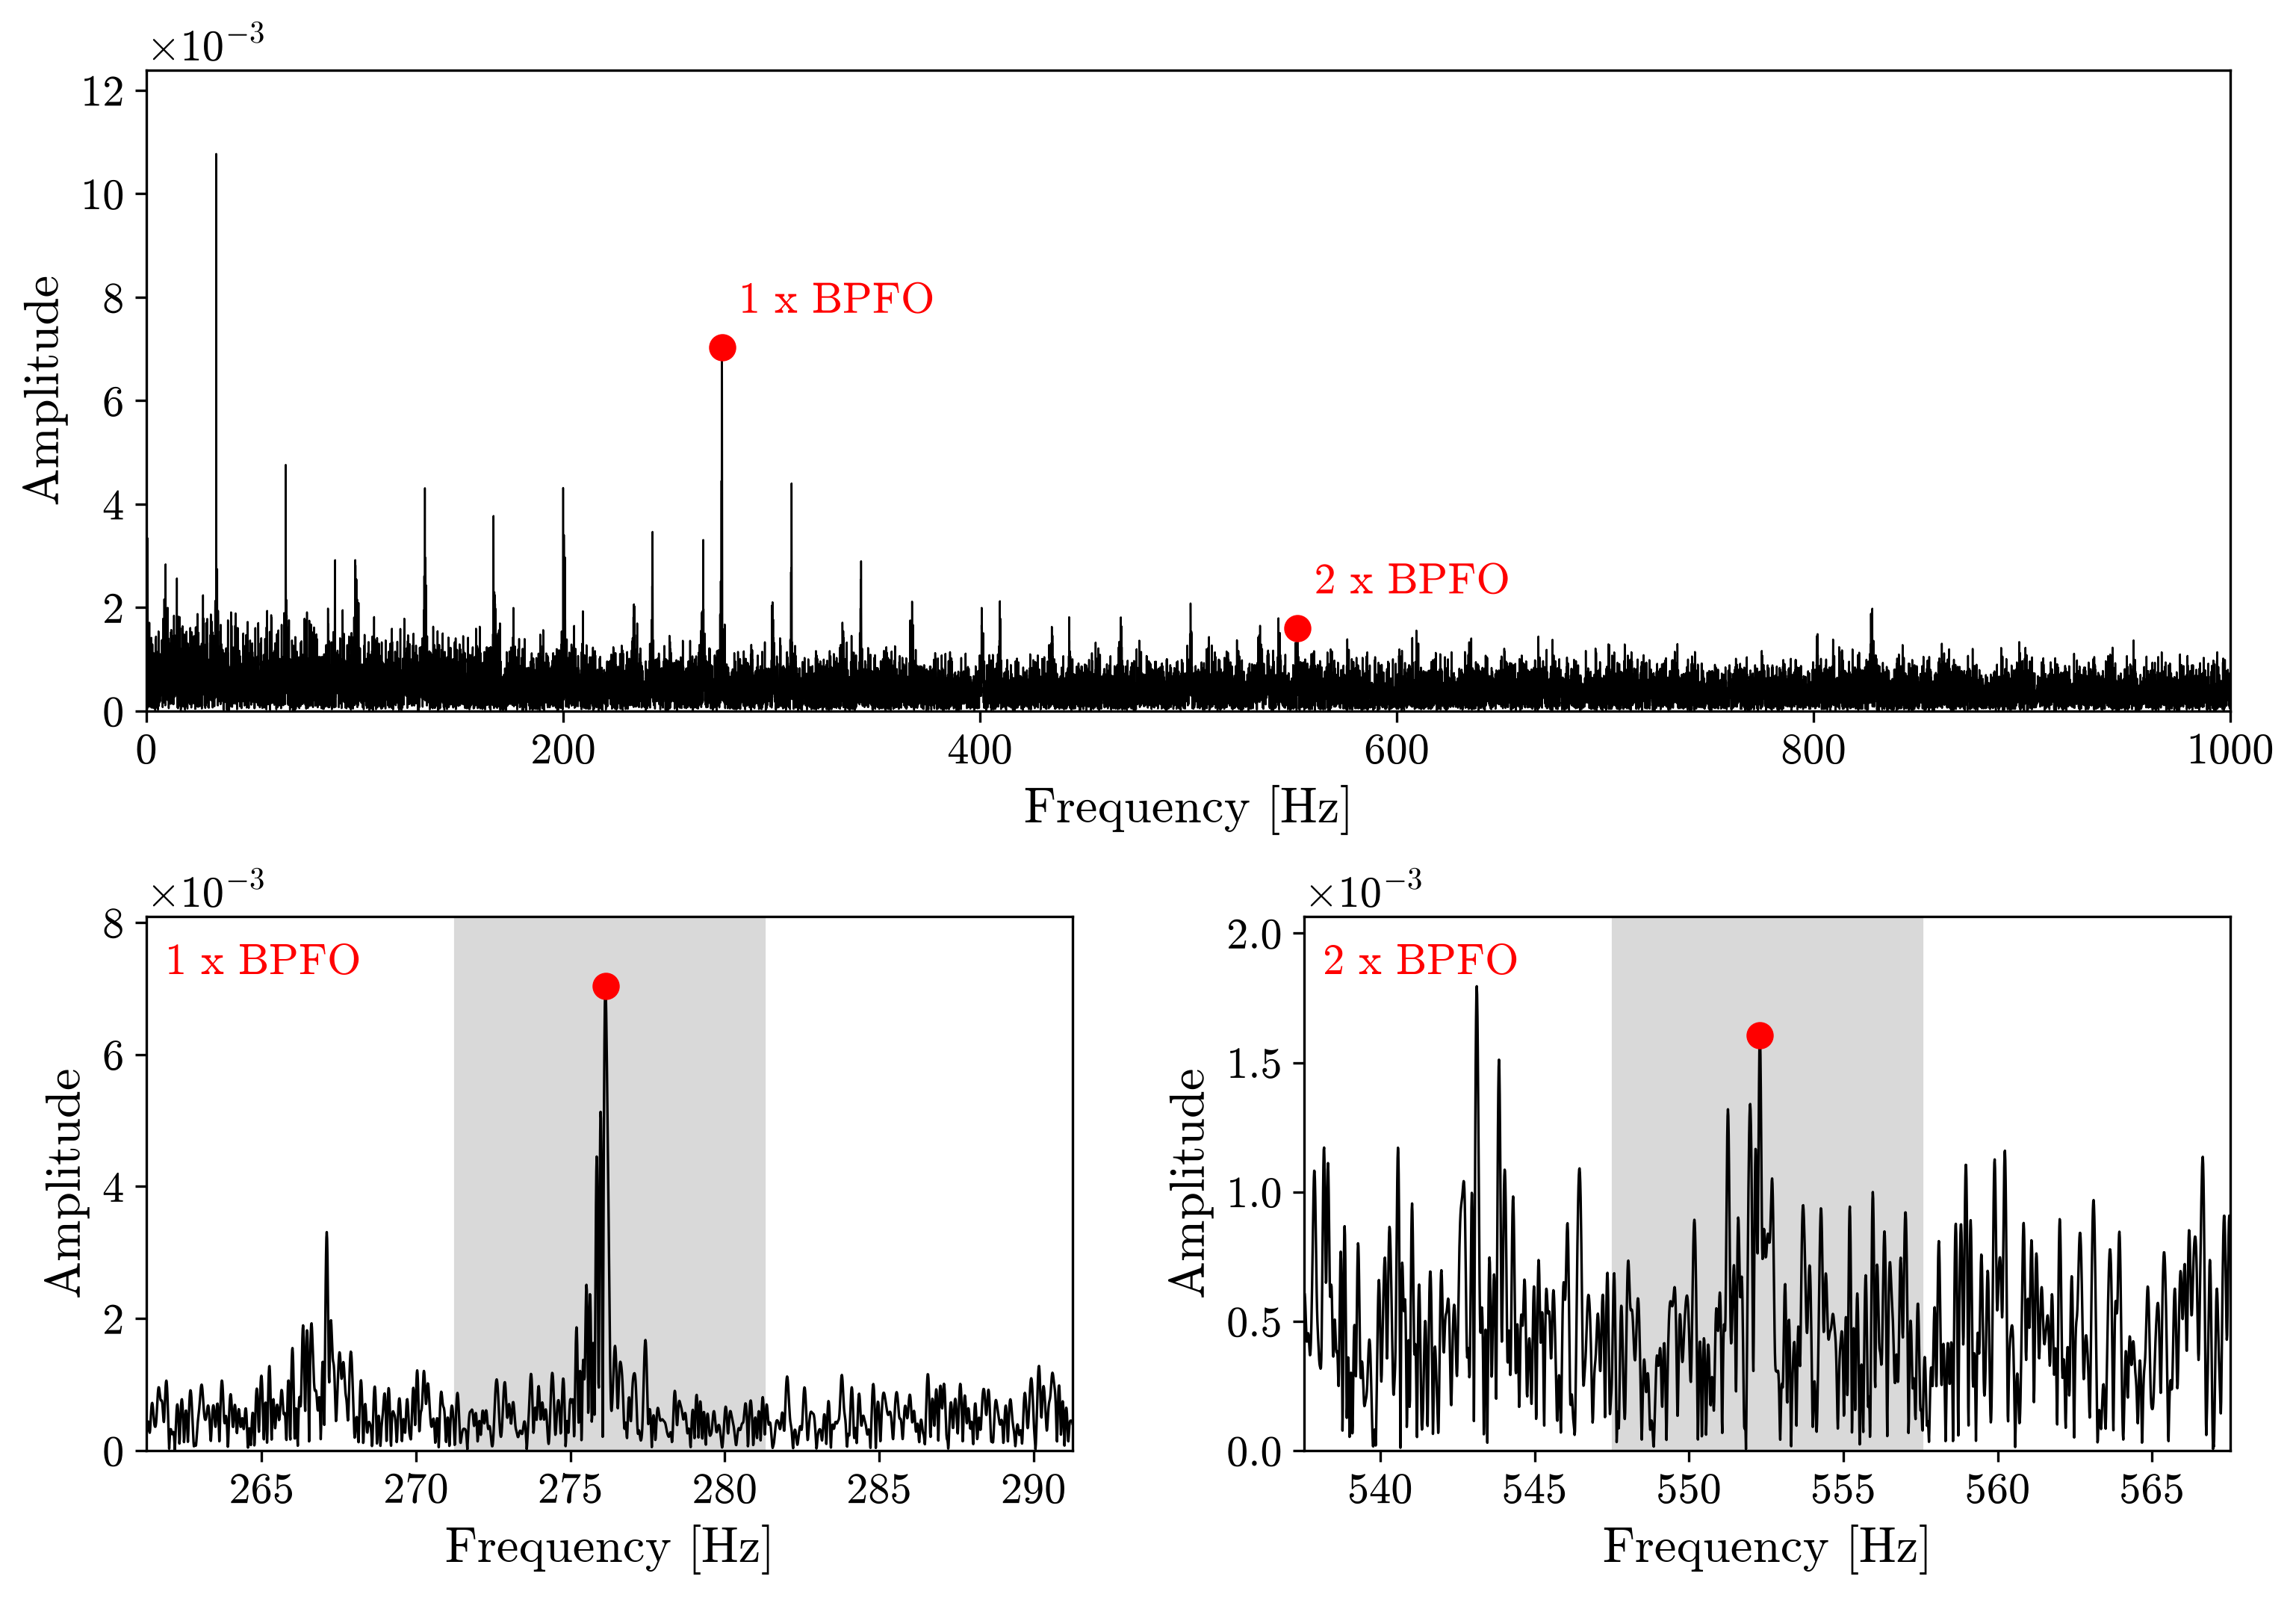

peaks_damaged_T2_C1_R1_segment01.png


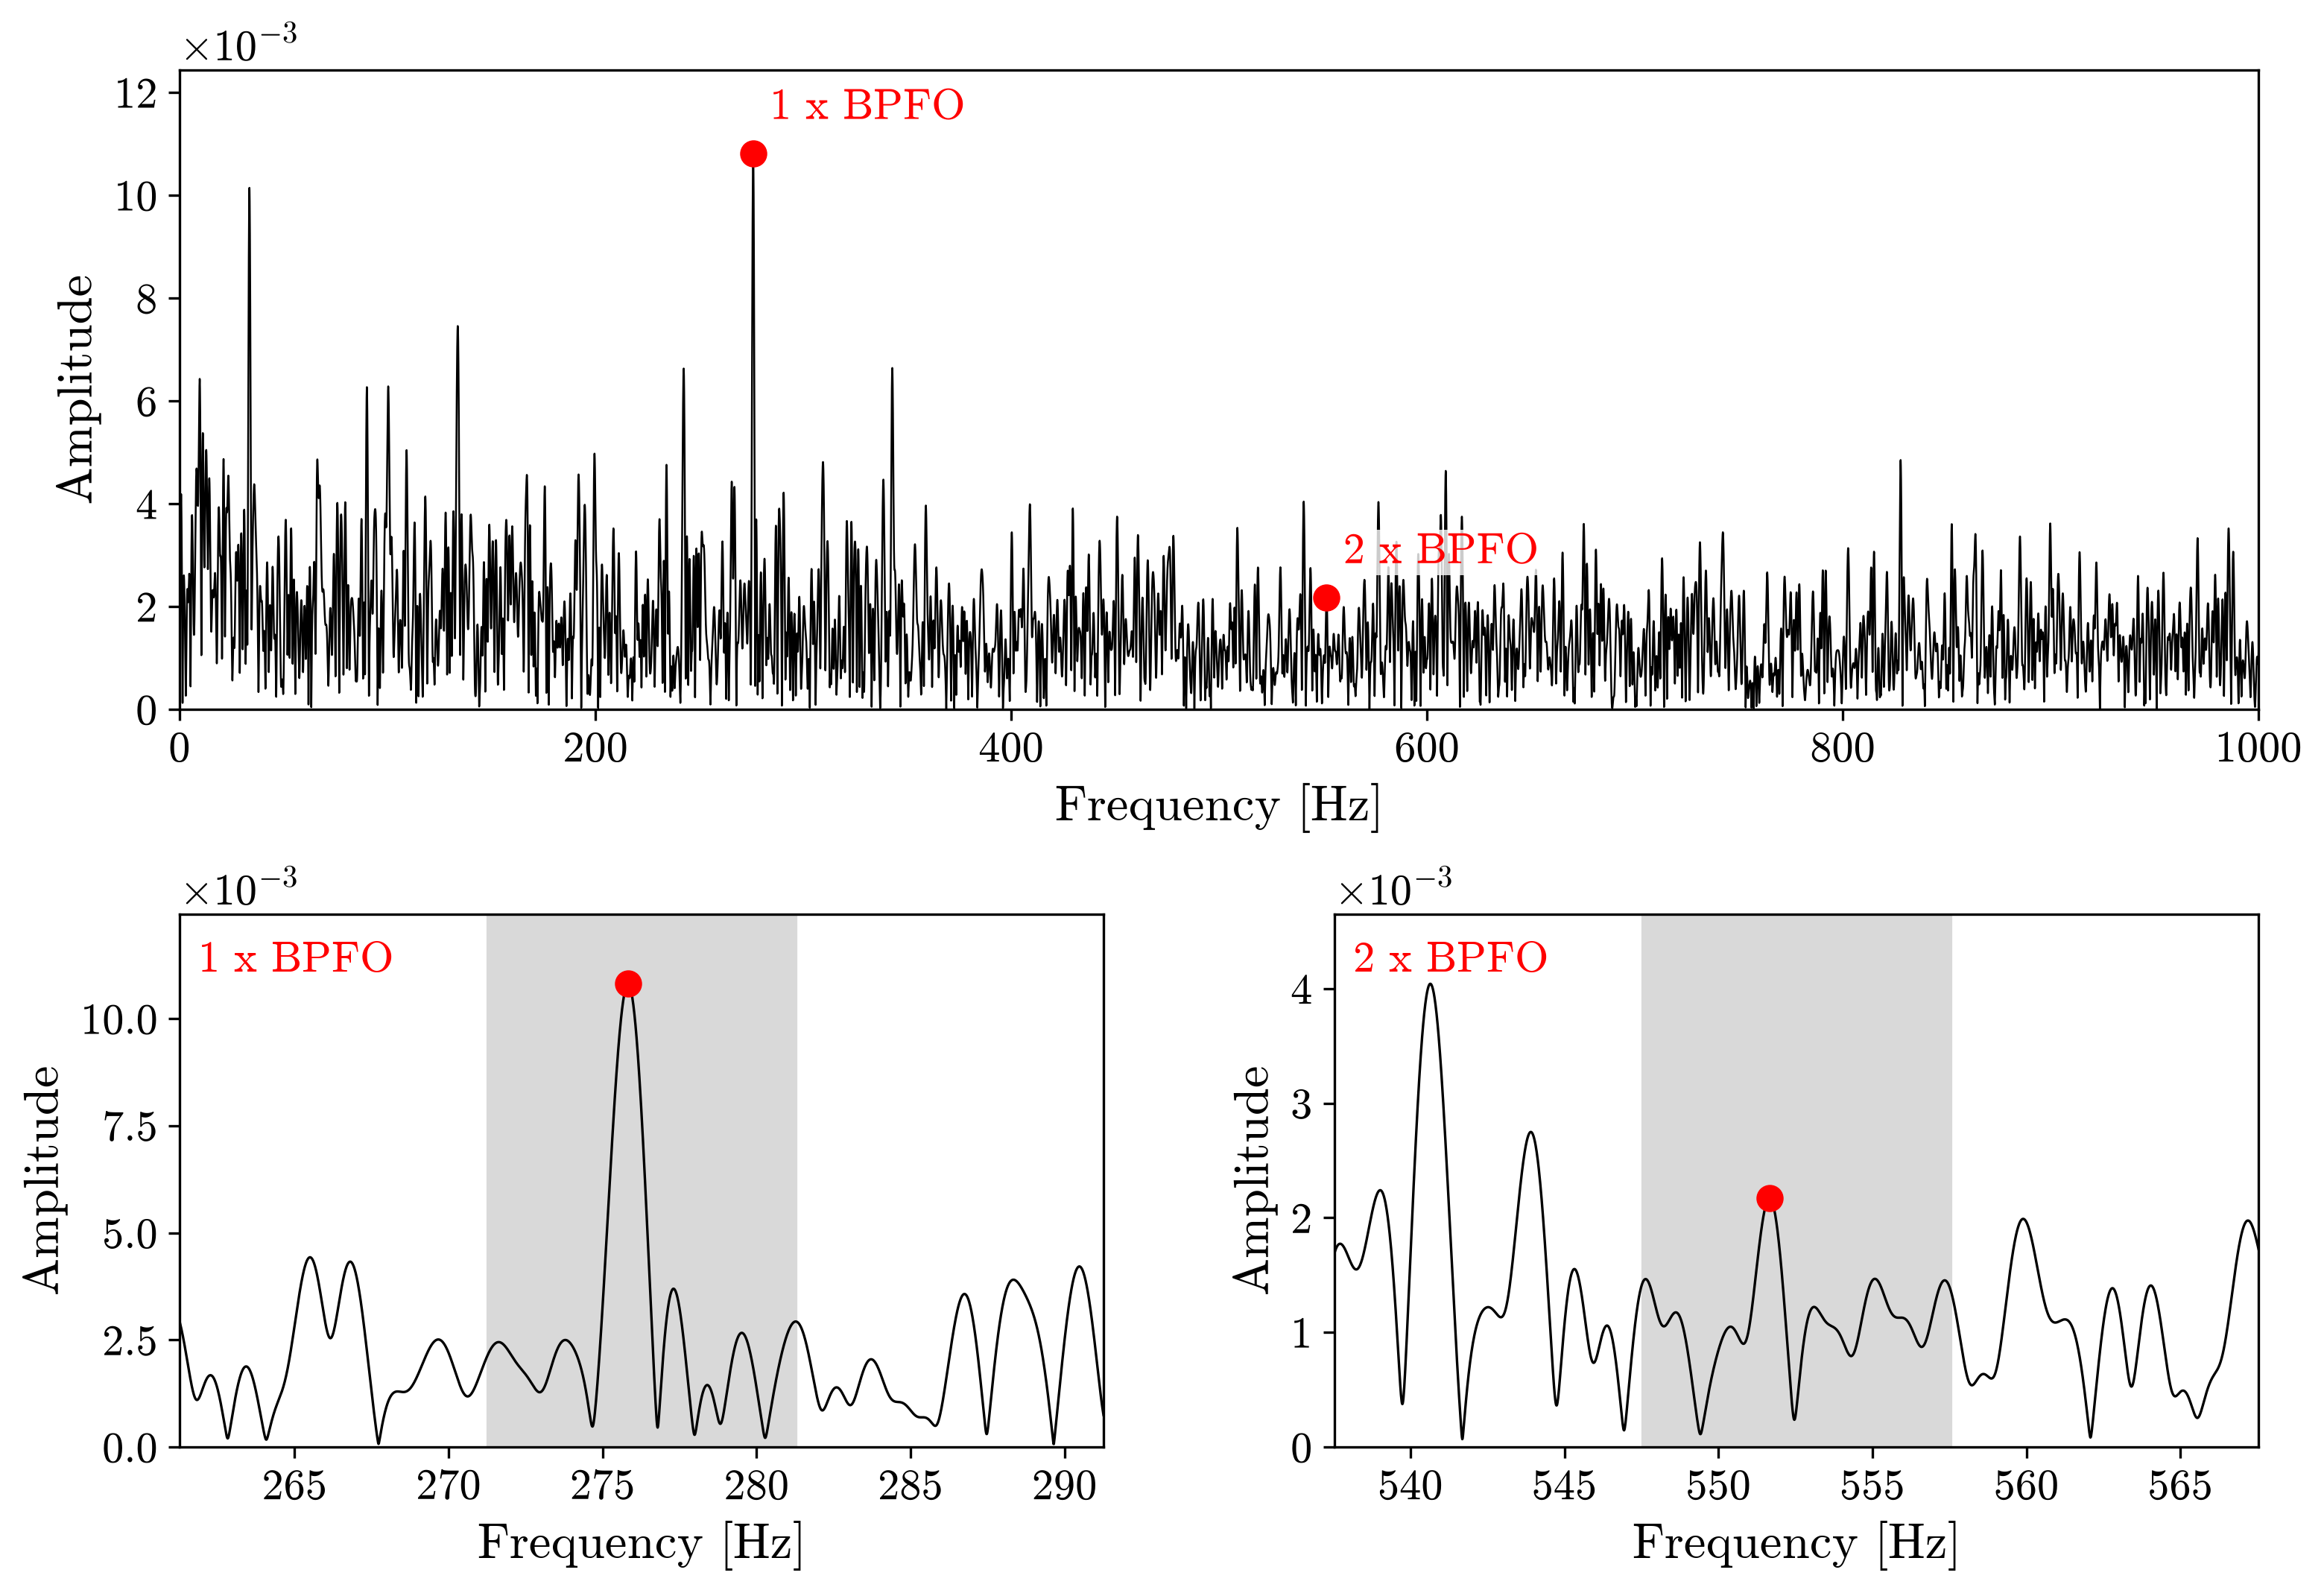

In [7]:
for h in uc.HEALTH_STATES:
    for part in ("full", "segment01"):
        p = cfg.subdir("peak_verification") / f"peaks_{h}_{cfg.representative_test}_C1_R1_{part}.png"
        print(p.name)
        display(Image(filename=str(p), width=900))